# 01 — Bond Mathematics: Discounting, Yield, and Forward Rates

**MIT 18.642 · Lecture 1 · Vasily Strela · Slides 18–25 (Fall 2024)**

These are original explanatory notes inspired by the lecture, with additional examples, derivations, and Python experiments. We assume no prior knowledge of bonds. The numerical examples are hypothetical and are not investment recommendations.

**Learning goals:** understand why money at different dates has different values; value zero-coupon and coupon bonds; distinguish coupon rate, current yield, and yield to maturity; interpret the yield curve; measure interest-rate sensitivity; and understand a forward rate agreement.

**Conventions:** Unless otherwise stated, annual compounding, annual coupon payments, deterministic promised cash flows, and a single discount rate are used for teaching. Real-world bond pricing may use multiple discount factors, day-count conventions, accrued interest, and credit adjustments.

**Source:** [MIT OCW 18.642 (Fall 2024)](https://ocw.mit.edu/courses/18-642-topics-in-mathematics-with-applications-in-finance-fall-2024/), Lecture 1, slides 18–25.

## 1. Before slide 19 — Essential vocabulary

- **Principal / face value / par value:** the amount a bond promises to repay at maturity, usually denoted $N$. Example: a bond with face value $\$1,000$ promises to repay $\$1,000$ at maturity. **Non-example:** its current market price need not equal $\$1,000$.
- **Issuer:** the government or company borrowing money by selling a bond. **Bondholder:** the investor lending money by buying the bond.
- **Maturity:** the date the bond's principal is due. **Term to maturity:** time remaining until that date.
- **Coupon:** a periodic interest payment promised by a coupon bond. A **zero-coupon bond** pays no periodic coupons.
- **Interest rate:** the price of borrowing money over time, typically quoted per year.
- **Cash flow:** money received or paid at a particular date. Bond pricing values a *sequence* of cash flows, not just a final total.

**Running example:** Alice buys a newly issued bond from a company for $\$950$. The company promises to pay her $1,000 in two years. Alice is the lender; the company is the borrower. She receives no interim payments. This is a zero-coupon bond.

**Check:** A share of Apple is an ownership claim, not a promise to repay a face value on a fixed maturity date.

## 2. Slide 19 — Time value of money and compounding

**Principle (time value of money).** A dollar available today can be invested, so it is generally worth more than an identical dollar received later, *given a positive relevant interest rate*. This does not mean a dollar today always buys more goods; inflation and risk are separate considerations.

**Simple interest:** interest is calculated on the original principal alone: $FV=P(1+rt)$.

**Compound interest:** earned interest itself earns interest. With annual compounding at constant rate $r$, after $n$ years:

$$FV=P(1+r)^n.$$

For $m$ compounding periods per year:

$$FV=P\left(1+\frac rm\right)^{mt}.$$

The continuously compounded limit is

$$FV=\lim_{m\to\infty}P\left(1+\frac rm\right)^{mt}=Pe^{rt}.$$

**Example:** $\$1,000$ at 5% for three years becomes $\$1,157.63$ under annual compounding, rather than $\$1,150$ under simple interest.

Reference: [Wikipedia — Compound interest](https://en.wikipedia.org/wiki/Compound_interest) (also linked on slide 19).

Simple interest: $1,150.00; annual compounding: $1,157.63


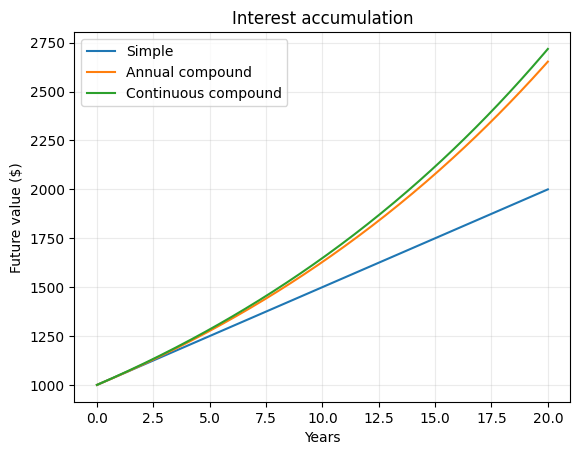

In [1]:
# Import NumPy for arrays and exponential functions.
import numpy as np
# Import Matplotlib for visualizing financial relationships.
import matplotlib.pyplot as plt
# Set an illustrative starting investment, annual rate, and investment horizon.
principal, rate, years = 1000.0, 0.05, 3
# Compute future values under simple and annual compound interest.
simple = principal * (1 + rate * years)
compound = principal * (1 + rate) ** years
# Print both values so the effect of interest-on-interest is visible.
print(f"Simple interest: ${simple:,.2f}; annual compounding: ${compound:,.2f}")
# Create a grid of times for a visual comparison.
t = np.linspace(0, 20, 201)
# Plot simple, annual, and continuous compounding at the same quoted rate.
plt.plot(t, principal * (1 + rate * t), label="Simple")
plt.plot(t, principal * (1 + rate) ** t, label="Annual compound")
plt.plot(t, principal * np.exp(rate * t), label="Continuous compound")
# Label the graph and display the result.
plt.xlabel("Years"); plt.ylabel("Future value ($)"); plt.title("Interest accumulation")
plt.legend(); plt.grid(alpha=0.25); plt.show()

### Discounting: going backwards in time

**Discounting** asks: what amount today would grow to a specified future amount? If $FV$ is paid after $n$ years and the relevant annual rate is $r$, its **present value** is

$$PV=\frac{FV}{(1+r)^n}.$$

The **discount factor** for maturity $n$ is the present value of one dollar delivered then:

$$D(n)=\frac{1}{(1+r)^n},\qquad PV=FV\,D(n).$$

Example: at 5%, $1,000$ due in two years has present value $1000/(1.05)^2\approx\$907.03$.

**Important assumption:** the discount rate must be appropriate to the cash flow's timing and risk. A risky corporate promise cannot automatically be valued using a risk-free Treasury rate.

**Exercise 1:** Find the present value of $2,000$ due in three years at 4% annual compounding. How would it change if the discount rate rose?


## An Application of Discounting: The Firm-Foundation Theory and John Burr Williams's Theory of Investment Value

### 1. The Firm-Foundation Theory

In *A Random Walk Down Wall Street*, Burton G. Malkiel discusses the **firm-foundation theory** of stock valuation.

The central idea is that a financial asset has an **intrinsic value** (also called *fundamental value*) determined by the economic benefits it is expected to generate in the future.

**Intrinsic value:** An estimate of what an asset is economically worth, based on its expected future cash flows and an appropriate discount rate.

This should be distinguished from its **market price**, which is the price at which buyers and sellers currently trade the asset.

The firm-foundation approach suggests that:

- If the market price is below the estimated intrinsic value, the asset may be undervalued.
- If the market price is above the estimated intrinsic value, the asset may be overvalued.
- An investor can use estimates of intrinsic value to make investment decisions.

However, intrinsic value is not directly observable. It depends on assumptions about future cash flows, risk, and discount rates.

### 2. John Burr Williams's Theory of Investment Value (1938)

In his book *The Theory of Investment Value* (1938), economist John Burr Williams developed a mathematical framework for valuing investments through **discounting future income**.

His central insight was that the value of an investment should be determined by the present value of the income it is expected to generate.

For bonds, the relevant income consists of coupon payments and repayment of principal.

For stocks, Williams emphasized future dividends.

This leads to a general valuation principle:

$$
\boxed{
V_0=\sum_{t=1}^{T}\frac{\mathbb{E}[CF_t]}{(1+r)^t}
}
$$

where:

- $V_0$ is the estimated intrinsic value today.
- $CF_t$ is the cash flow received at time $t$.
- $\mathbb{E}[CF_t]$ is the expected cash flow at time $t$.
- $r$ is the annual discount rate.
- $T$ is the investment horizon.

For this introductory model, we assume a constant discount rate and annual cash flows.

For risky investments, the discount rate must appropriately account for risk. In more advanced asset-pricing models, valuation can instead be expressed using risk-adjusted probabilities or stochastic discount factors.

### 3. Example: Valuing a Stock Using Future Dividends

Suppose Alice is considering purchasing a share in a hypothetical company.

She estimates that the company will distribute the following dividends:

| Year | Expected dividend |
|---|---:|
| 1 | $\$5$ |
| 2 | $\$6$ |
| 3 | $\$7$ |

Alice also estimates that she can sell the share for $110 at the end of Year 3.

Suppose she uses an annual discount rate of 10%.

The estimated intrinsic value is:

$$
V_0=
\frac{5}{1.10}
+
\frac{6}{(1.10)^2}
+
\frac{7+110}{(1.10)^3}.
$$

Therefore,

$$
\boxed{V_0\approx \$97.41}.
$$

The final term includes both the dividend received in Year 3 and the expected selling price.

Suppose the current market price is $85.

According to Alice's assumptions:

$$
V_0-P_{\text{market}}
=
97.41-85
=
\$12.41.
$$

Alice estimates that the share is undervalued by approximately $12.41.

However, this conclusion depends on the accuracy of her forecasts and her choice of discount rate.

### 4. The Dividend Discount Model

Williams's approach leads naturally to the **Dividend Discount Model (DDM)**.

If a stock is held indefinitely, its theoretical value can be written as:

$$
\boxed{
V_0=\sum_{t=1}^{\infty}
\frac{\mathbb{E}[D_t]}{(1+r)^t}
}
$$

where $D_t$ denotes the dividend paid in year $t$.

This formula assumes that the discounted terminal value of the stock vanishes as the investment horizon approaches infinity.

**Why dividends rather than earnings?**

A company's earnings are not necessarily distributed to shareholders immediately.

The company may retain some earnings to finance future investments.

Those investments may eventually generate larger future dividends.

Thus, retained earnings can contribute to the stock's intrinsic value through their effect on expected future distributions.

A company paying no dividends today can therefore still have substantial intrinsic value.

### 5. Special Case: Dividends Growing at a Constant Rate

Suppose the expected dividend next year is $D_1$, and dividends subsequently grow at a constant annual rate $g$.

Then:

$$
D_t=D_1(1+g)^{t-1}.
$$

Substituting into the dividend discount formula gives:

$$
V_0=
\sum_{t=1}^{\infty}
\frac{D_1(1+g)^{t-1}}{(1+r)^t}.
$$

This is a geometric series.

Provided that $r>g$, we obtain:

$$
\boxed{V_0=\frac{D_1}{r-g}}.
$$

This is known as the **Gordon Growth Model**, a later development of the dividend-discount approach associated with Williams.

**Example**

Suppose:

- Next year's expected dividend is $D_1=\$4$.
- The expected annual dividend growth rate is $g=3\%$.
- The required return is $r=8\%$.

Then:

$$
V_0=\frac{4}{0.08-0.03}
=\boxed{\$80}.
$$

The model estimates the stock's intrinsic value at $80.

The condition $r>g$ is essential for convergence.

In practice, constant dividend growth forever is a strong assumption, so more sophisticated models often allow different growth rates over different periods.

### 6. Connection to Bond Mathematics

The mathematical principle is the same for bonds and stocks: **discount future payments to obtain their present value**.

For a coupon bond with annual coupon $C$, face value $N$, maturity $T$, and constant discount rate $r$:

$$
P_{\text{bond}}
=
\sum_{t=1}^{T}\frac{C}{(1+r)^t}
+
\frac{N}{(1+r)^T}.
$$

For a stock under the dividend discount model:

$$
V_{\text{stock}}
=
\sum_{t=1}^{\infty}
\frac{\mathbb{E}[D_t]}{(1+r)^t}.
$$

The principal differences are:

| Bond | Stock |
|---|---|
| Contractually specified coupon payments | Dividends are generally discretionary and uncertain |
| Usually has a specified maturity | Common stock generally has no maturity |
| Principal is contractually due at maturity | No general promise to repay the purchase price |
| Subject to interest-rate and credit risk | Subject to business, market, and other risks |

Therefore, although the mathematical structure is similar, forecasting stock cash flows is generally more uncertain than calculating the promised cash flows of a conventional fixed-rate bond.

### 7. A Limitation of the Firm-Foundation Theory

The firm-foundation approach provides a mathematical framework for estimating value, but it does not guarantee that market prices will equal those estimates.

Two investors may estimate different intrinsic values because they use different assumptions about:

- Future earnings and dividends.
- Growth rates.
- Discount rates.
- Business and economic risks.

Furthermore, market prices can differ from estimated intrinsic values for extended periods.

**Key takeaway:** Discounting provides a mathematical method for valuing future income, but the reliability of the resulting valuation depends on the assumptions used.

---

### Exercise: Investment Value and Discounting

1. A stock is expected to pay a dividend of $\$5$ next year and $\$6$ the following year. If Alice expects to sell the stock for $100 at the end of Year 2 and uses a discount rate of 10%, calculate its estimated intrinsic value.

2. Suppose a company is expected to pay a dividend of $3 next year, growing at 2% annually forever. If the required return is 7%, calculate its intrinsic value using the Gordon Growth Model.

3. Why can a company that currently pays no dividends still have a positive intrinsic value under Williams's theory?

4. What is the fundamental mathematical similarity between pricing a coupon bond and valuing a stock using the dividend discount model?

5. If two investors agree on all future expected dividends but disagree about the appropriate discount rate, will they necessarily estimate the same intrinsic value? Explain.




In [2]:
# Choose an illustrative future payment, discount rate, and maturity.
future_payment, discount_rate, maturity = 2000.0, 0.04, 3
# Discount the promised payment to its value today.
present_value = future_payment / (1 + discount_rate) ** maturity
# Report the result rounded to cents.
print(f"Present value: ${present_value:,.2f}")

Present value: $1,777.99


## 3. Slide 20 — Zero-coupon (discount) bonds

**Definition.** A **zero-coupon bond** is a bond that promises a single payment of its face value $N$ at maturity $T$, with **no periodic interest payments** in between. It is often issued or traded for less than face value; the difference between purchase price and redemption value provides the investor's return if the issuer pays as promised.

**Timeline:** Today: investor pays $P$ → During the bond's life: no coupons → Maturity: issuer pays $N$.

With annual yield $y$ and $n$ years remaining, the price is

$$\boxed{P=\frac{N}{(1+y)^n}}.$$

**Example:** A two-year zero-coupon bond with $N=\$1,000$ and yield 5% costs about $\$907.03$. At maturity the issuer promises $\$1,000$. The difference, about $92.97, is not an annual coupon: it is the total dollar increase between purchase price and maturity payment.

**Risks:** The issuer could default; the market price can change before maturity; inflation can reduce purchasing power. The quoted yield is not a guarantee if the bond is sold early or defaults.

Zero-coupon price: $907.03


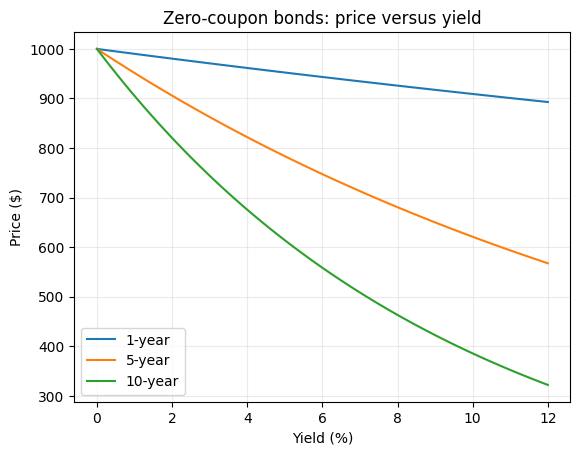

In [3]:
# Define a simple zero-coupon bond price function with annual compounding.
def zero_coupon_price(face_value, yield_rate, years):
    # Discount the face value to the present.
    return face_value / (1 + yield_rate) ** years
# Display the price for the running example.
print(f"Zero-coupon price: ${zero_coupon_price(1000, 0.05, 2):,.2f}")
# Create a range of annual yields between zero and 12%.
yields = np.linspace(0, 0.12, 121)
# Plot the price-yield relationship for several maturities.
for years in (1, 5, 10):
    # Evaluate prices at each yield for this maturity.
    prices = zero_coupon_price(1000, yields, years)
    # Draw the curve with a maturity label.
    plt.plot(100 * yields, prices, label=f"{years}-year")
# Explain the axes and show the figure.
plt.xlabel("Yield (%)"); plt.ylabel("Price ($)"); plt.title("Zero-coupon bonds: price versus yield")
plt.legend(); plt.grid(alpha=0.25); plt.show()

## 4. Slide 21 — Coupon bonds

**Definition.** A coupon bond promises periodic coupon payments and repayment of face value at maturity. If the face value is $N$ and the **annual coupon rate** is $c$, then the annual dollar coupon is $C=cN$ (for annual payments).

**Example:** A five-year $\$1,000$ bond with a 6% annual coupon rate pays $\$60$ at the end of each year and repays $\$1,000$ at the end of year five. At the last date, the investor receives **both** the final $\$60$ coupon and the $1,000 principal.

If all payments are discounted at a common annual yield $y$:

$$P=\sum_{t=1}^{n}\frac{C}{(1+y)^t}+\frac{N}{(1+y)^n}.$$

Using the geometric-series formula (for $y\neq0$):

$$\boxed{P=C\frac{1-(1+y)^{-n}}{y}+N(1+y)^{-n}}.$$

At $y=0$, the continuous limit gives $P=nC+N$.

**Key distinction:** The **coupon rate** is fixed by the bond's contract; the **market yield** can change every day as its price changes. A coupon payment is not the same as a bond's total investment return.

**Par, premium, discount:** A bond trades **at par** if $P=N$, **at a premium** if $P>N$, and **at a discount** if $P<N$. Under the simple annual model, if $y=c$ the bond prices at par; if $y<c$ it trades at a premium; if $y>c$ it trades at a discount.

**Exercise 2:** A three-year bond has $N=\$1,000$, coupon rate 4%, and yield 6%. List each promised cash flow and calculate its price. Is it above or below par?

Yield 3%: price $1,137.39
Yield 6%: price $1,000.00
Yield 9%: price $883.31


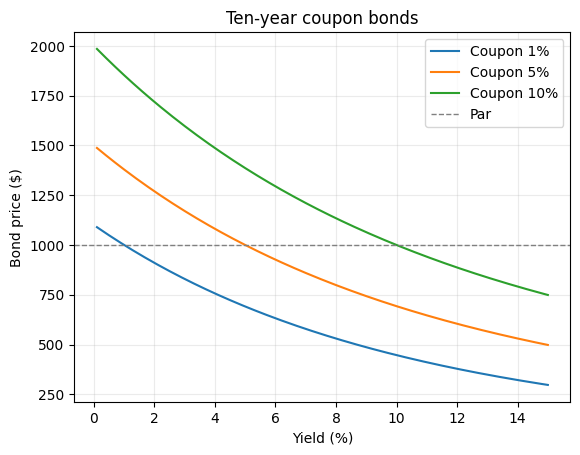

In [4]:
# Define the price of a fixed-coupon bond with annual payments.
def coupon_bond_price(face_value, coupon_rate, yield_rate, years):
    # Compute the dollar coupon from the quoted coupon rate.
    coupon = face_value * coupon_rate
    # Create the dates when coupons are paid.
    payment_times = np.arange(1, years + 1)
    # Discount each coupon and add the discounted face value.
    return np.sum(coupon / (1 + yield_rate) ** payment_times) + face_value / (1 + yield_rate) ** years
# Compare coupon-bond prices for three possible market yields.
for y in (0.03, 0.06, 0.09):
    # Print the price of a five-year 6%-coupon bond.
    print(f"Yield {y:.0%}: price ${coupon_bond_price(1000, 0.06, y, 5):,.2f}")
# Build a yield grid for a price-yield plot.
yields = np.linspace(0.001, 0.15, 150)
# Plot several coupon rates, holding maturity and face value fixed.
for coupon_rate in (0.01, 0.05, 0.10):
    # Compute the price at each market yield.
    prices = [coupon_bond_price(1000, coupon_rate, y, 10) for y in yields]
    # Plot this coupon rate's price-yield curve.
    plt.plot(yields * 100, prices, label=f"Coupon {coupon_rate:.0%}")
# Draw a par-price reference line.
plt.axhline(1000, color="gray", linestyle="--", linewidth=1, label="Par")
# Label the graph and display it.
plt.xlabel("Yield (%)"); plt.ylabel("Bond price ($)"); plt.title("Ten-year coupon bonds")
plt.legend(); plt.grid(alpha=0.25); plt.show()

## 5. Slide 22 — What exactly is a bond's yield?

**Intuition:** Yield translates a bond's *price today* and its *promised future payments* into an annualized rate. It lets us compare bonds with different prices and cash-flow schedules, but it must be interpreted carefully.

### Three rates that beginners often confuse

1. **Coupon rate** $c=C/N$: annual coupon divided by face value. Set by the bond's contract. Example: a $\$50$ annual coupon on $\$1,000$ face value means a **5% coupon rate**.
2. **Current yield** $C/P$: annual coupon divided by the bond's *current market price*. Example: if that bond trades for $\$950$, its current yield is $50/950 \approx 5.26\%$. This ignores repayment at maturity and timing of other payments.
3. **Yield to maturity (YTM)** $y$: the single discount rate that makes the present value of **all remaining promised payments** equal the bond's observed market price:

$$P=\sum_{t=1}^{n}\frac{C}{(1+y)^t}+\frac{N}{(1+y)^n}.$$

For a zero-coupon bond, solve explicitly:

$$\boxed{y=\left(\frac{N}{P}\right)^{1/n}-1}.$$

For a coupon bond, we generally solve this equation numerically. **The yield is inferred from price**, not an extra payment made by the issuer.

**Example:** The same 5%-coupon bond can trade below par if investors require a 6% yield. Its coupon remains $50; its price falls to make the *overall promised cash flows* consistent with 6% YTM.

**When does YTM represent a realized return?** In this simplified fixed-rate setting, matching the quoted YTM over the full holding period requires the issuer to make all promised payments and, for a coupon bond, coupon reinvestment at the assumed rate (or an appropriate total-return calculation). Selling early introduces price risk. Taxes, fees, defaults, and reinvestment rates also matter.

**Why price and yield move in opposite directions:** For a positive future payment $X_t$, its discounted value $X_t/(1+y)^t$ decreases as $y$ rises. Summing such terms gives a decreasing price function for ordinary fixed-cash-flow bonds.

**Exercise 3:** A two-year zero-coupon bond with $\$1,000$ face value sells for $\$900$. Find its YTM. Explain why the result differs from simply dividing the $\$100$ gain by the $\$900$ purchase price.

### Yield to Maturity (YTM): Definition and Example

**Yield to Maturity (YTM)** is the annualized rate of return implied by a bond's current market price and its promised future payments, assuming the bond is held until maturity and all contractual payments are made.

Mathematically, YTM is the **discount rate that makes the present value of all future bond payments equal to its current market price**.

#### Example: Alice Purchases a Government Bond

Suppose Alice is considering purchasing a hypothetical government bond with the following characteristics:

| Property | Value |
|---|---|
| Face value (principal) | $\$1,000$ |
| Annual coupon rate | 5% |
| Annual coupon payment | $\$50$ |
| Time to maturity | 3 years |
| Current market price | $\$950$ |

**Face value:** The amount the issuer promises to repay at maturity.

**Coupon rate:** The annual coupon payment expressed as a percentage of the bond's face value.

Since the coupon rate is 5%, Alice receives:

$$
C=0.05\times1000=\$50
$$

each year.

If Alice purchases the bond for $950 and holds it until maturity, the promised payments are:

| Time | Cash flow |
|---|---:|
| Today | $-\$950$ |
| End of Year 1 | $+\$50$ |
| End of Year 2 | $+\$50$ |
| End of Year 3 | $+\$1,050$ |

The final payment includes the $\$50$ coupon and the $\$1,000$ principal repayment.

#### Calculating Yield to Maturity

Let $y$ denote the yield to maturity.

We want to find the discount rate $y$ satisfying:

$$
950=\frac{50}{1+y}+\frac{50}{(1+y)^2}+\frac{1050}{(1+y)^3}.
$$

This equation generally cannot be solved using a simple algebraic formula, so we solve it numerically.

For this bond, the solution is approximately:

$$
\boxed{y=6.90\%}.
$$

Therefore, **the bond's yield to maturity is approximately 6.90% per year**.

#### Why Is the YTM Higher Than the Coupon Rate?

Notice that:

- The coupon rate is 5%.
- The yield to maturity is approximately 6.90%.

The reason is that Alice purchases the bond for **$\$950$**, but receives **$\$1,000$** in principal at maturity.

In addition to the annual coupon payments, Alice benefits from the $50 difference between the purchase price and the face value.

Thus, her return comes from two sources:

1. **Coupon income:** The annual $\$50$ payments.
2. **Capital gain at maturity:** The $\$50$ difference between the principal repayment and her purchase price.

The YTM incorporates both sources of return and accounts for the timing of each payment.

It is not obtained simply by adding the coupon rate and the percentage capital gain.

#### Relationship Between Bond Price and YTM

For a conventional fixed-rate bond:

| Market price | Relationship | YTM compared with coupon rate |
|---|---|---|
| Below face value | Discount bond | YTM > Coupon rate |
| Equal to face value | Par bond | YTM = Coupon rate |
| Above face value | Premium bond | YTM < Coupon rate |

For example, if the same bond trades at its face value of $1,000, its YTM is exactly 5%.

If investors are willing to pay more than $1,000 for the bond, its YTM falls below 5%.

This illustrates the **inverse relationship between bond prices and yields**.

#### Important Distinction: Coupon Rate vs. Current Yield vs. YTM

For Alice's bond:

**1. Coupon rate**

$$
\text{Coupon Rate}=\frac{50}{1000}\times100=5\%.
$$

**2. Current yield**

Current yield compares the annual coupon payment with the current market price:

$$
\text{Current Yield}=\frac{50}{950}\times100\approx5.26\%.
$$

**3. Yield to maturity**

YTM accounts for all remaining coupon payments, the repayment of principal, and the timing of those payments:

$$
\boxed{\text{YTM}\approx6.90\%}.
$$

Hence,

$$
\boxed{
\text{Coupon Rate}=5\%
<
\text{Current Yield}=5.26\%
<
\text{YTM}=6.90\%
}
$$

for this particular bond.

**Important:** YTM is a rate implied by promised cash flows, not a guarantee of the investor's realized return. Defaults, selling before maturity, and the rates available for reinvesting coupons can affect the actual investment outcome.

---

### Exercise: Understanding Yield to Maturity

1. Alice purchases a zero-coupon bond for $\$900$. The bond pays $\$1,000$ at maturity in two years. Calculate its annual yield to maturity.

2. A bond has a face value of $\$1,000$ and an annual coupon rate of 6%. If its market price is $1,000, what is its YTM, assuming annual coupon payments?

3. Suppose the market price of Alice's bond increases from $\$950$ to $\$980$ while its promised future payments remain unchanged. Does its YTM increase or decrease? Explain.

4. Why is the current yield generally different from the yield to maturity?


In [5]:
# Import a root finder to infer yield from a coupon bond's price.
from scipy.optimize import brentq
# Define a function that finds the yield consistent with an observed price.
def yield_to_maturity(price, face_value, coupon_rate, years):
    # Form the difference between theoretical and observed prices.
    def pricing_error(yield_rate):
        # Return zero when the trial yield correctly prices the bond.
        return coupon_bond_price(face_value, coupon_rate, yield_rate, years) - price
    # Find a root for annual yield above -100%; this range is illustrative.
    return brentq(pricing_error, -0.95, 2.0)
# Price a bond at a known yield, then recover that yield numerically.
observed_price = coupon_bond_price(1000, 0.05, 0.06, 5)
# Compute the annual coupon and current yield.
annual_coupon = 1000 * 0.05
current_yield = annual_coupon / observed_price
# Recover the yield to maturity from its price.
computed_ytm = yield_to_maturity(observed_price, 1000, 0.05, 5)
# Compare three distinct financial rates.
print(f"Price: ${observed_price:,.2f}; coupon rate: 5.00%; current yield: {current_yield:.2%}; YTM: {computed_ytm:.2%}")

Price: $957.88; coupon rate: 5.00%; current yield: 5.22%; YTM: 6.00%


## 6. Slide 23 — Yield curves and the term structure

**Yield curve:** a graph of yield (vertical axis) against time to maturity (horizontal axis) for bonds that are otherwise comparable, such as US Treasury securities. **Term structure** means how interest rates vary across maturities.

- **Upward-sloping (normal):** longer-maturity yields exceed shorter-maturity yields.
- **Flat:** yields are similar across maturities.
- **Inverted:** some shorter-maturity yields exceed longer-maturity yields.

**Example:** If a three-month Treasury yield is 5% and a ten-year Treasury yield is 4%, the ten-year minus three-month **term spread** is $4\%-5\%=-1$ percentage point. This segment is inverted.

The lecture's slide 23 compares historical Treasury curves. The curves are *snapshots at different dates*, not trajectories of one bond's yield over time.

### Why does an inverted yield curve matter?

**Verified historical association:** US Treasury yield-curve inversions have frequently preceded US recessions. The [Federal Reserve Bank of San Francisco (2018)](https://www.frbsf.org/research-and-insights/publications/economic-letter/2018/03/economic-forecasts-with-yield-curve/) discusses the strong historical record; the [Cleveland Fed yield-curve indicator](https://www.clevelandfed.org/indicators-and-data/yield-curve-and-predicted-gdp-growth) also notes **false positives**, including the prolonged 2022–2024 inversion. The [New York Fed](https://www.newyorkfed.org/research/capital_markets/ycfaq.html) tracks a model based on the ten-year minus three-month spread.

**Interpretation:** An inversion is a *signal of elevated recession risk*, **not a theorem, a guarantee, or proof that the curve causes recession**. We'll return to the economic mechanisms later.

### From yields to discount factors (preview)

For a zero-coupon yield $z(T)$ with annual compounding, $D(T)=(1+z(T))^{-T}$. Coupon-bond yields to maturity are **not** generally interchangeable with zero-coupon spot rates at each cash-flow date. **Bootstrapping** means solving sequentially for discount factors from market prices of instruments with known payments; we illustrate a simple two-year case below.

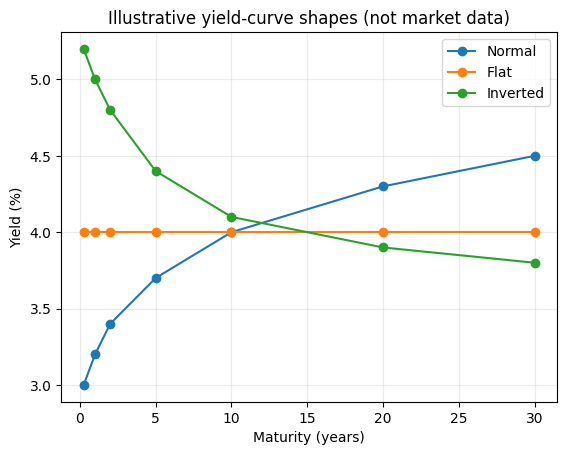

In [6]:
# Specify hypothetical yields for different maturities (not observed market data).
maturities = np.array([0.25, 1, 2, 5, 10, 20, 30])
# Specify an illustrative normal yield curve.
normal = np.array([3.0, 3.2, 3.4, 3.7, 4.0, 4.3, 4.5])
# Specify an illustrative flat yield curve.
flat = np.full_like(maturities, 4.0)
# Specify an illustrative inverted yield curve.
inverted = np.array([5.2, 5.0, 4.8, 4.4, 4.1, 3.9, 3.8])
# Draw the three curve shapes for comparison.
for label, curve in (("Normal", normal), ("Flat", flat), ("Inverted", inverted)):
    # Plot yield versus time to maturity.
    plt.plot(maturities, curve, marker="o", label=label)
# Label the axes and identify the data as illustrative.
plt.xlabel("Maturity (years)"); plt.ylabel("Yield (%)"); plt.title("Illustrative yield-curve shapes (not market data)")
plt.legend(); plt.grid(alpha=0.25); plt.show()

### Worked example: bootstrapping two discount factors

Suppose a one-year zero-coupon bond with face value $100$ costs $96$. Its one-year discount factor is

$$D(1)=96/100=0.96.$$

Now suppose a two-year bond pays $5$ at year one and $105$ at year two, and its market price is $99$. Since each cash flow has its own discount factor,

$$99=5D(1)+105D(2).$$

Solving gives $D(2)=(99-5\times0.96)/105\approx0.89714$. The two-year zero rate is $z(2)=D(2)^{-1/2}-1\approx5.58\%$.

This is the basic idea of **bootstrapping**: use previously identified shorter-maturity discount factors to isolate the next unknown. Real implementations require consistent payment dates, accrued-interest conventions, and suitable instruments.

In [7]:
# Infer the first discount factor from a one-year zero-coupon bond.
d1 = 96 / 100
# Infer the second discount factor from a two-year coupon bond.
d2 = (99 - 5 * d1) / 105
# Convert the second discount factor into an annual-compounded zero rate.
z2 = d2 ** (-1 / 2) - 1
# Display the discount factors and implied two-year zero rate.
print(f"D(1)={d1:.5f}; D(2)={d2:.5f}; two-year zero rate={z2:.2%}")

D(1)=0.96000; D(2)=0.89714; two-year zero rate=5.58%


## 7. Slide 24 — Duration and convexity: bond price sensitivity

Bond prices fall as yields rise, but **how much**? Two related concepts quantify the effect.

### Duration

**Macaulay duration** is the present-value-weighted average time at which a bond's promised cash flows are received. For cash flows $CF_t$ at annual dates:

$$D_{\mathrm{Mac}}=\frac{\sum_{t=1}^n t\,CF_t(1+y)^{-t}}{P}.$$

**Modified duration** measures first-order sensitivity of price to an annual yield change:

$$D_{\mathrm{mod}}=\frac{D_{\mathrm{Mac}}}{1+y}=-\frac1P\frac{dP}{dy}.$$

Thus, for a *small* yield change $\Delta y$ (in decimal units),

$$\frac{\Delta P}{P}\approx-D_{\mathrm{mod}}\Delta y.$$

**Example:** Modified duration 4 means a yield increase of 0.01 (one percentage point) predicts approximately a 4% price decrease for a sufficiently small change. Duration is **not** the time until the bond is fully repaid.

**Special case:** For an $n$-year zero-coupon bond, all present value arrives at year $n$, so $D_{\mathrm{Mac}}=n$ and $D_{\mathrm{mod}}=n/(1+y)$.

### Convexity

Duration gives a tangent-line approximation; the price-yield curve is usually curved. **Convexity** measures the second-order curvature:

$$\mathcal C=\frac1P\frac{d^2P}{dy^2}=\frac{\sum_{t=1}^n t(t+1)CF_t(1+y)^{-t-2}}{P}.$$

A second-order approximation is

$$\frac{\Delta P}{P}\approx-D_{\mathrm{mod}}\Delta y+\tfrac12\mathcal C(\Delta y)^2.$$

This is **yield convexity** for a standard fixed-cash-flow bond with annual compounding; embedded options can change the behavior. The lecture also mentions a continuous-payment par-bond case, which we leave for a later extension.

**Exercise 4:** Why does a ten-year zero-coupon bond generally have greater interest-rate sensitivity than a one-year zero-coupon bond at the same yield?

In [8]:
# Create a function returning Macaulay duration, modified duration, and convexity.
def bond_sensitivities(face_value, coupon_rate, yield_rate, years):
    # Enumerate annual cash-flow dates.
    times = np.arange(1, years + 1)
    # Construct the coupon payments at every date.
    cash_flows = np.full(years, face_value * coupon_rate, dtype=float)
    # Add repayment of face value to the last payment.
    cash_flows[-1] += face_value
    # Compute the present value of each payment.
    pv_flows = cash_flows / (1 + yield_rate) ** times
    # Sum discounted payments to obtain the bond price.
    price = pv_flows.sum()
    # Calculate Macaulay duration as a present-value-weighted mean time.
    macaulay = np.sum(times * pv_flows) / price
    # Convert Macaulay duration to modified duration.
    modified = macaulay / (1 + yield_rate)
    # Calculate annual-compounded convexity from the second derivative.
    convexity = np.sum(times * (times + 1) * pv_flows / (1 + yield_rate) ** 2) / price
    # Return all measures together.
    return price, macaulay, modified, convexity
# Evaluate an illustrative five-year bond with 5% coupon and 6% yield.
price, dmac, dmod, conv = bond_sensitivities(1000, 0.05, 0.06, 5)
# Print the three sensitivity measures.
print(f"Price=${price:,.2f}; Macaulay={dmac:.3f} years; modified={dmod:.3f}; convexity={conv:.3f}")
# Choose a one-percentage-point rise in yield.
delta_y = 0.01
# Compute the first-order relative price change.
first_order = -dmod * delta_y
# Add the convexity correction for the second-order estimate.
second_order = first_order + 0.5 * conv * delta_y ** 2
# Compute the actual repricing under the higher yield.
actual = coupon_bond_price(1000, 0.05, 0.06 + delta_y, 5) / price - 1
# Compare the approximations to exact repricing.
print(f"Actual: {actual:.3%}; duration-only: {first_order:.3%}; duration + convexity: {second_order:.3%}")

Price=$957.88; Macaulay=4.535 years; modified=4.278; convexity=23.410
Actual: -4.163%; duration-only: -4.278%; duration + convexity: -4.161%


## 8. Slide 25 — Forward rates and forward rate agreements (FRAs)

### Before the definition: why would anyone agree on a future interest rate?

Imagine Alice's company knows it must borrow $1,000,000 **three months from now**, for a further three months. It worries that borrowing rates may rise before the loan begins. The company wants to reduce uncertainty about the *future interest expense*.

**Spot interest rate:** a rate associated with lending or borrowing beginning now. **Forward interest rate:** a rate fixed today for a borrowing/lending period beginning in the future. A **forward rate agreement (FRA)** is a derivative contract in which two counterparties agree on an interest rate for a specified future period; it typically settles the difference between the agreed rate and a future reference rate **in cash**, rather than exchanging the loan principal.

**Important distinction from the slide's timeline:** The diagram on slide 25 illustrates a future-starting loan with principal $N$ at $t$ and repayment $N(1+F_{t,T}(T-t))$ at $T$ under simple interest. A standard FRA is often a *cash-settled agreement on that rate*, **not** itself a transfer of $N$ in principal.

### Deriving the forward rate from discount factors

Let $D(t)$ and $D(T)$ be today's discount factors for payments at times $t$ and $T$, with $T>t$. Under a simple-interest convention over the period $\delta=T-t$ (year fraction), the no-arbitrage forward rate $F_{t,T}$ satisfies

$$\boxed{1+F_{t,T}\delta=\frac{D(t)}{D(T)}}$$

and hence

$$\boxed{F_{t,T}=\frac{D(t)/D(T)-1}{\delta}}.$$

**Why?** The ratio $D(t)/D(T)$ is the future-period growth factor implied by today's discount prices. A different freely available forward rate would create inconsistent prices under the simplified no-arbitrage assumptions.

### Example: Alice locks a future borrowing rate

Suppose Alice expects to borrow $\$1,000,000$ for three months starting in three months. The agreed FRA rate is 5% annually, with a simple year fraction $\delta=0.25$.

If the reference rate at the start is **7%**, the extra loan interest relative to 5% would be

$$1{,}000{,}000(0.07-0.05)(0.25)=\$5{,}000.$$

A suitable **pay-fixed / receive-floating FRA** offsets that difference economically. Standard FRAs commonly settle *at the start* of the borrowing period, discounting this end-of-period difference:

$$\boxed{\text{FRA settlement at }t=\frac{N\delta(L-K)}{1+L\delta}},$$

where $L$ is the observed reference rate and $K$ is the contracted rate. Here the settlement is about $4,914.00$ at $t$, whose value at $T$ when accumulated at the 7% reference rate is $5,000$.

If the reference rate falls below 5%, Alice instead pays on the FRA, giving up the benefit of lower borrowing rates. **Hedging stabilizes outcomes rather than guaranteeing a profit.**

**Caveats:** Real FRA markets specify reference rates, day-count fractions, fixing dates, settlement rules, credit/collateral terms, and sometimes use different discounting conventions. The formulas here are teaching approximations.

**Non-example:** Buying a two-year fixed-rate bond today is not an FRA: it is buying a security with promised cash flows rather than entering a derivative tied to a future floating-rate fixing.

**Exercise 5:** If $D(1)=0.96$ and $D(2)=0.90$, compute the simple one-year forward rate from year 1 to year 2. If the realized floating rate exceeds the FRA rate, who benefits from a pay-fixed/receive-floating FRA?

In [9]:
# Define a forward-rate function using discount factors and year fraction.
def simple_forward_rate(discount_start, discount_end, year_fraction):
    # Calculate the rate implied by the ratio of discount factors.
    return (discount_start / discount_end - 1) / year_fraction
# Compute the illustrative one-year forward rate between years one and two.
forward_rate = simple_forward_rate(0.96, 0.90, 1.0)
# Print the implied forward rate.
print(f"Implied one-year forward rate: {forward_rate:.3%}")
# Set notional, year fraction, agreed rate, and observed floating rate.
notional, fraction, fixed_rate, floating_rate = 1_000_000, 0.25, 0.05, 0.07
# Compute the standard simplified start-of-period FRA settlement for receive-floating.
settlement = notional * fraction * (floating_rate - fixed_rate) / (1 + floating_rate * fraction)
# Show the settlement and its end-of-period equivalent.
print(f"FRA payment at start: ${settlement:,.2f}; equivalent at end: ${settlement * (1 + floating_rate * fraction):,.2f}")

Implied one-year forward rate: 6.667%
FRA payment at start: $4,914.00; equivalent at end: $5,000.00


## 9. Summary and exercises for independent study

| Idea | Main formula or interpretation |
|---|---|
| Compound growth | $FV=P(1+r)^n$ |
| Present value | $PV=FV/(1+r)^n$ |
| Zero-coupon bond | $P=N/(1+y)^n$ |
| Coupon bond | $P=\sum C/(1+y)^t+N/(1+y)^n$ |
| Yield to maturity | Discount rate that reproduces observed price from promised cash flows |
| Term spread | Long-maturity yield minus short-maturity yield |
| Modified duration | $-(1/P)\,dP/dy$ |
| Convexity | $(1/P)\,d^2P/dy^2$ |
| Simple forward rate | $[D(t)/D(T)-1]/(T-t)$ |

**Further exercises:**

1. Explain in ordinary language why a bond's price changes even when its coupon and face value are fixed.
2. Derive the geometric-series expression for a coupon bond's price from the sum of discounted cash flows.
3. Compare a zero-coupon and a coupon bond with equal maturity and YTM: which typically has higher Macaulay duration, and why?
4. Create two hypothetical yield curves with identical ten-year yield but different three-month yields. What happens to their term spreads?
5. Explain why a forward rate inferred from today's prices is **not** a guaranteed prediction of the future realized rate.

**Suggested notebook workflow:** derive each equation by hand; run each code cell; change one parameter; describe the observed pattern; identify which simplifying assumptions were used.

## References and attribution

**Primary lecture source**

### References

1. Williams, John Burr (1938). *The Theory of Investment Value*. Harvard University Press. Particularly the discussion of evaluation by the rule of present worth.
   https://openlibrary.org/books/OL6369682M/The_theory_of_investment_value

2. Malkiel, Burton G. *A Random Walk Down Wall Street*. Chapter 1, discussion of the firm-foundation theory and the castle-in-the-air theory.

3. CFA Institute (2012). *The Theory of Investment Value: Four Enduring Takeaways on Dividend Investing from John Burr Williams*.
   https://rpc.cfainstitute.org/blogs/enterprising-investor/2012/dividend-investing-and-the-lasting-influence-of-john-burr-williams-the-theory-of-investment-value

4. MIT 18.642 (Fall 2024). Lecture 1, *Discounting and Bond Math*, slides 19–22.

**Additional explanatory sources**

2. [Wikipedia, *Compound interest*](https://en.wikipedia.org/wiki/Compound_interest) — additional background linked by slide 19.
3. Federal Reserve Bank of San Francisco, Bauer and Mertens (2018), [*Economic Forecasts with the Yield Curve*](https://www.frbsf.org/research-and-insights/publications/economic-letter/2018/03/economic-forecasts-with-yield-curve/) — historical association between inversions and recessions.
4. Federal Reserve Bank of Cleveland, [*Yield Curve and Predicted GDP Growth*](https://www.clevelandfed.org/indicators-and-data/yield-curve-and-predicted-gdp-growth) — indicator background and false positives, including 2022–2024.
5. Federal Reserve Bank of New York, [*The Yield Curve as a Leading Indicator*](https://www.newyorkfed.org/research/capital_markets/ycfaq.html) — ten-year minus three-month term spread and recession probability framework.

**Note:** Hypothetical plots are not observed market data. Bond and FRA formulas use deliberately simplified conventions to clarify the mathematics.


### Solutions to Exercises: Investment Value and Discounting

#### Exercise 1: Intrinsic Value of a Stock

The estimated intrinsic value is:

$$
V_0=\frac{5}{1.10}+\frac{6+100}{(1.10)^2}
$$

$$
\boxed{V_0\approx \$92.15}
$$

#### Exercise 2: Gordon Growth Model

Using the Gordon Growth Model:

$$
V_0=\frac{D_1}{r-g}
$$

$$
V_0=\frac{3}{0.07-0.02}
$$

$$
\boxed{V_0=\$60}
$$

#### Exercise 3: Why Can a Company Paying No Dividends Have Positive Intrinsic Value?

A company may retain its earnings to finance future investments and business expansion.

These investments can generate higher profits and potentially larger dividends in the future.

Under Williams's theory, the stock's intrinsic value depends on the **present value of expected future dividends**, not necessarily on dividends paid today.

Therefore, a company paying no dividends currently can still have positive intrinsic value if investors expect it to distribute cash to shareholders in the future.

#### Exercise 4: Similarity Between Bond Pricing and Stock Valuation

Both are based on the **time value of money**: the present value of an asset is calculated by discounting its future cash flows.

For a coupon bond:

$$
P_{\text{bond}}=
\sum_{t=1}^{T}\frac{C}{(1+r)^t}
+\frac{N}{(1+r)^T}.
$$

For a stock:

$$
V_{\text{stock}}=
\sum_{t=1}^{\infty}\frac{\mathbb{E}[D_t]}{(1+r)^t}.
$$

The main difference is that conventional fixed-rate bonds have contractually specified payments, whereas future stock dividends are generally uncertain.

#### Exercise 5: Effect of Different Discount Rates

**No.** Two investors using different discount rates will generally obtain different intrinsic values, even if they agree on all expected future dividends.

For fixed positive future cash flows:

$$
V_0(r)=\sum_{t=1}^{\infty}\frac{\mathbb{E}[D_t]}{(1+r)^t}.
$$

As the discount rate $r$ increases, the present value decreases.

Therefore:

- A **higher discount rate** produces a **lower intrinsic value**.
- A **lower discount rate** produces a **higher intrinsic value**.

This illustrates why the choice of discount rate is important in fundamental valuation.



### Solutions to Exercises: Understanding Yield to Maturity

#### Exercise 1: Yield to Maturity of a Zero-Coupon Bond

**Answer:**

$$
\boxed{y=\left(\frac{1000}{900}\right)^{1/2}-1\approx 5.41\%}
$$

#### Exercise 2: Yield to Maturity of a Par Bond

**Answer:**

$$
\boxed{\text{YTM}=6\%}
$$

#### Exercise 3: Effect of an Increase in Bond Price on YTM

**Answer: The yield to maturity decreases.**

The YTM is the discount rate that equates the present value of the bond's future cash flows to its current market price.

For a bond with fixed future cash flows:

$$
P=\sum_{t=1}^{T}\frac{CF_t}{(1+y)^t}.
$$

As the yield $y$ increases, the present value $P$ decreases, and vice versa.

Therefore, when Alice's bond price increases from $950 to $980, its YTM must decrease because its promised future cash flows remain unchanged.

This illustrates the **inverse relationship between bond prices and yields**.

#### Exercise 4: Difference Between Current Yield and Yield to Maturity

**Answer:**

The **current yield** considers only the annual coupon payment relative to the bond's current market price:

$$
\text{Current Yield}=\frac{\text{Annual Coupon}}{\text{Market Price}}.
$$

In contrast, **yield to maturity (YTM)** is the discount rate that equates the present value of all remaining coupon payments and the principal repayment to the current market price.

The key difference is that:

- **Current yield** considers coupon income but ignores the gain or loss arising from the difference between the purchase price and the face value.
- **YTM** accounts for both coupon payments and principal repayment, including the timing of these cash flows.

For example, a bond purchased below its face value generates an additional gain if held until maturity and repaid in full. This gain is reflected in YTM but not in current yield.

Thus, current yield and YTM generally differ whenever a bond trades at a discount or premium.
